# tiny-yolov4-voc sur voc — inférence

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/voc/tiny-yolov4-voc_infer.ipynb)

Rôle : inférence ; palier **R** au premier passage (`SUBSET = 50`), **N** sur le split complet (4952 images, `SUBSET = 0`). **Full run by default** (`SUBSET = 0`, `INT8 = True`); set `SUBSET = 50` for a quick try. Tâches : [T24.6](../../docs/tasks/M24-yolov4-tiny.md) ;
notebooks : [M14](../../docs/tasks/M14-notebooks.md).

Prérequis :
- données : `data/VOCdevkit/VOC2007/ImageSets/Main/test.txt` — tools/get_voc.sh
- poids : `build/notebooks/voc/tiny-yolov4-voc/[runs/<run>/]final.weights` — notebooks/voc/tiny-yolov4-voc_train.ipynb ou _sweep.ipynb
- cfg : `build/m11/cfg/tiny-yolov4-voc.cfg` — notebooks/voc/tiny-yolov4-voc_train.ipynb (préparation)

Chaque étape affiche la commande `python tools/…` qu'elle lance : un résultat se
reproduit en ligne de commande. Sorties dans `build/notebooks/voc/tiny-yolov4-voc/eval/`, jamais dans `results/`
(une mAP sur `SUBSET` images n'est pas publiable, règles de M12). Notebook généré par
`python -m tools.notebooks` (`make notebooks`) : modifier le gabarit
`tools/notebooks/gabarits.py`, pas ce fichier.

## Paramètres

In [1]:
NET          = 'build/m11/cfg/tiny-yolov4-voc.cfg'  # nom de CFG_FILES ou cfg (relative à la racine)
DATASET      = 'voc'  # clé de DATASETS
SPLIT        = None  # None : split d'évaluation du jeu
WEIGHTS      = None  # None : final.weights du run RUN ; ou un chemin
DEVICE       = 'gpu'  # cpu | gpu (entraînement seulement ; le reste sur CPU)
SUBSET       = 0  # images évaluées ; 0 : split complet (palier N)
SIZE         = None  # entrée LxH (ex. '640x192') ; None : celle de la cfg
RESIZE       = 'stretch'  # stretch (référence M12) | letterbox
METRIC       = None  # None : celle du jeu (coco pour coco et flir)
DATA_ROOT    = None  # racine du jeu ; None : data/<jeu> (Colab : dossier Drive)
RUNS_DIR     = 'build/notebooks/voc/tiny-yolov4-voc'  # runs des notebooks _train et _sweep
RUN          = None  # None : le plus récent ; ex. 'train', 'b16-sall', 'b8-s500'
COMPARE      = False  # évalue tous les runs et les compare (T14.11)
INT8         = True  # volet entier : calibration et mAP INT8 (T14.4)
CALIB_IMAGES = 500  # images de calibration (split calib du jeu)
ACT_HIST     = False  # histogrammes d'activations L00-L04 (T11.3)
HW           = False  # volet matériel (demande INT8) : export, golden C++, C-sim sur SUBSET images, mAP aux trois stades (T8.2, T24.5)
DRIVE_DIR    = '/content/drive/MyDrive/EmbeddedCV'  # Colab : archives data/<jeu>.tar ; None : pas de Drive
JOBS         = None  # processus des évaluations ; None : un par cœur CPU, plafonné par la mémoire (runtime TPU de Colab : des dizaines)
SHOW         = 6  # images affichées
OUT          = 'build/notebooks/voc/tiny-yolov4-voc/eval'  # sorties du notebook
REPO_URL     = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab : dépôt cloné
REV          = 'main'  # Colab : révision

## Environnement

Local : rien n'est installé ni téléchargé, la cellule vérifie les prérequis et
s'arrête avec la commande à lancer. Colab : clone du dépôt, installation, CuPy si
`DEVICE = "gpu"`, poids, puis données par `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<jeu>.tar` ou téléchargement direct ; ExDark et FLIR : archive
seulement, faite sur le PC par `tools/get_datasets.sh pack <jeu>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone d'une session précédente : remis à REV (notebook et code du même commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules importés avant la mise à jour
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # Runtime CPU : pas de pilote, CuPy dirait « cudaErrorInsufficientDriver ».
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("runtime Colab sans GPU : créer un nouveau serveur Colab "
                               "de type GPU (T4, L4 ou A100), ou DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # version du pilote
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("racine du dépôt introuvable : ouvrir le notebook depuis notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
from tools.notebooks import colab, runs

if COLAB and DRIVE_DIR:  # runs entraînés sur Colab : copiés dans <DRIVE_DIR>/runs/
    env.mount_drive(DRIVE_DIR)
    colab.restore_outputs(RUNS_DIR, DRIVE_DIR)
RUNS = runs.find_runs(RUNS_DIR)
print(f"runs de {RUNS_DIR} :\n{runs.listing(RUNS)}")
CHOSEN = None
if WEIGHTS is None:
    CHOSEN = runs.pick(RUNS_DIR, RUN, hint='notebooks/voc/tiny-yolov4-voc_train.ipynb ou _sweep.ipynb')
    WEIGHTS, OUT = CHOSEN.weights, f"{OUT}/{CHOSEN.name}"
    print(f"run choisi : {CHOSEN.name} ({WEIGHTS})")
env.prepare(DATASET, WEIGHTS, NET, DATA_ROOT, COLAB, hint='notebooks/voc/tiny-yolov4-voc_train.ipynb ou _sweep.ipynb',
            drive_dir=DRIVE_DIR)
Path(OUT).mkdir(parents=True, exist_ok=True)

dépôt E:\EmbeddedComputervision @ 9a21d9a (modifié) ; Python 3.13.5 ; NumPy 2.5.4 ; backend gpu
GPU : 1 visible(s), CuPy 14.2.0
runs de build/notebooks/voc/tiny-yolov4-voc :
  train        build\notebooks\voc\tiny-yolov4-voc\final.weights  (2026-10-22 15:37)
  b16-s500     build\notebooks\voc\tiny-yolov4-voc\runs\b16-s500\final.weights  (2026-10-22 13:25)
  b16-sall     build\notebooks\voc\tiny-yolov4-voc\runs\b16-sall\final.weights  (2026-10-22 13:29)
  b32-s500     build\notebooks\voc\tiny-yolov4-voc\runs\b32-s500\final.weights  (2026-10-22 13:38)
  b32-sall     build\notebooks\voc\tiny-yolov4-voc\runs\b32-sall\final.weights  (2026-10-22 13:47)
  b48-s500     build\notebooks\voc\tiny-yolov4-voc\runs\b48-s500\final.weights  (2026-10-22 14:01)
  b48-sall     build\notebooks\voc\tiny-yolov4-voc\runs\b48-sall\final.weights  (2026-10-22 14:16)
  b8-s500      build\notebooks\voc\tiny-yolov4-voc\runs\b8-s500\final.weights  (2026-10-22 13:14)
  b8-sall      build\notebooks\voc\tiny-yolov4-vo

## Réseau et poids

`yolo.models.tiny_yolo.build` et `yolo.io.darknet_weights.load_darknet_weights`.

In [3]:
import json

import numpy as np
from IPython.display import Markdown, display
from PIL import Image

from tools.detect import draw
from tools.notebooks.matrice import SPLIT_IMAGES, palier
from yolo.data import datasets
from yolo.data.letterbox import input_size, parse_size, size_label
from yolo.infer.pipeline import detect, preprocess
from yolo.io.darknet_weights import load_darknet_weights
from yolo.models.tiny_yolo import build

net = build(NET)
load_darknet_weights(net, WEIGHTS)
size = input_size(net.net, parse_size(SIZE) if SIZE else None)
channels = net.net["input"][0]
family, names = datasets.model_family(DATASET, net.net["classes"])
print(f"{NET} : {net.net['classes']} classes ({family}), entrée {size_label(size)}, "
      f"{channels} canal(aux) ; poids {WEIGHTS}")

build/m11/cfg/tiny-yolov4-voc.cfg : 20 classes (voc), entrée 416×416, 3 canal(aux) ; poids build\notebooks\voc\tiny-yolov4-voc\final.weights


## Détections sur quelques images

`yolo.infer.pipeline.preprocess` et `detect` (seuil de la démo), boîtes de
`tools/detect.py:draw`.

000001 : 1 détections


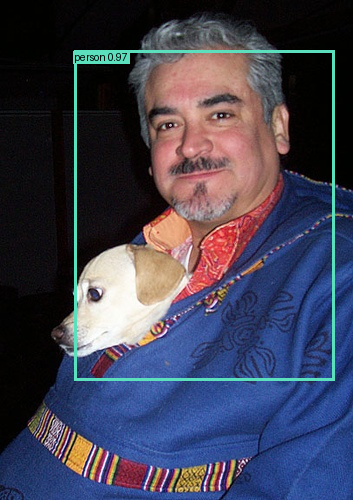

000002 : 1 détections


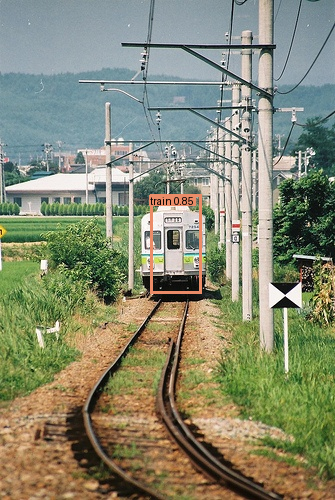

000003 : 0 détections


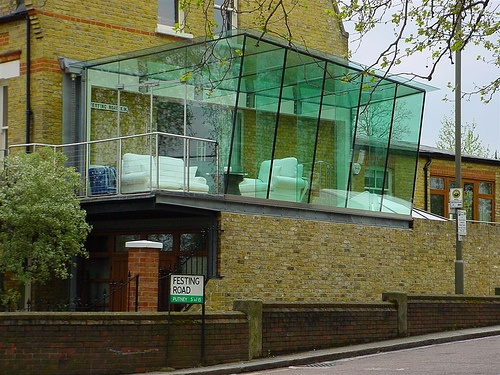

000004 : 3 détections


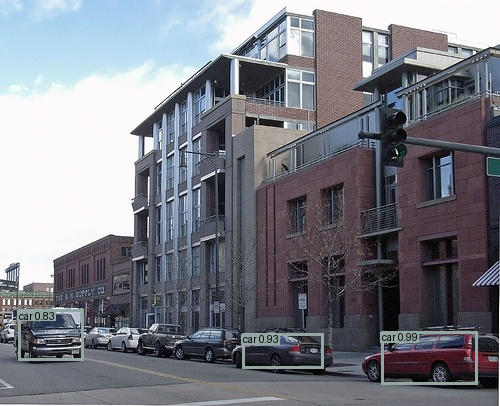

000006 : 3 détections


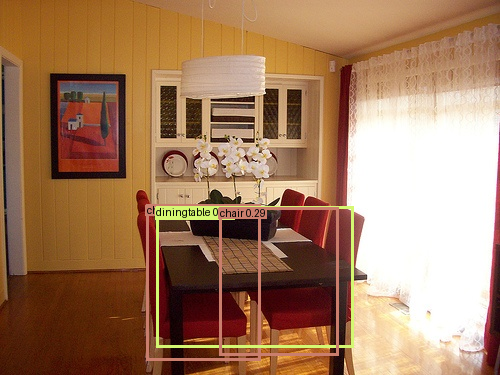

000008 : 1 détections


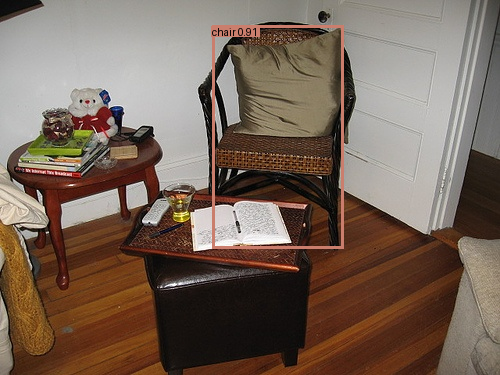

In [4]:
for s in datasets.load(DATASET, DATA_ROOT, SPLIT)[:SHOW]:
    with Image.open(s["image"]) as img:
        x, wh = preprocess(img, size, RESIZE, "pil", channels)
        boxes, scores, labels = detect(net, x[None], [wh], RESIZE)[0]
        shown = draw(img, boxes, scores, labels, names)
    shown.thumbnail((640, 640))
    print(f"{s['id']} : {len(labels)} détections")
    display(shown)

## mAP flottante (T14.3)

`tools/eval_voc.py`, métrique du jeu (`Dataset.metric` ; COCO et FLIR : AP@[.5:.95]
et AP50). Courbes PR du mode automatique de M13 (métrique VOC).

Le run choisi est évalué dans `RUNS_DIR/eval/<run>/`, comme par la comparaison
plus bas, qui réutilise ce résultat : une mAP déjà calculée pour ce `SUBSET` n'est
pas recalculée.

toutes les images : palier N (règles de M12)
$ python tools/eval_voc.py --net build/m11/cfg/tiny-yolov4-voc.cfg --weights 'build\notebooks\voc\tiny-yolov4-voc\final.weights' --dataset voc --resize stretch --subset 0 --out 'build\notebooks\voc\tiny-yolov4-voc\eval\train\dets_sall' --markdown 'build\notebooks\voc\tiny-yolov4-voc\eval\train\map_float_sall.md' --jobs 16
200/4952 images       9 s  (47 ms/image)
400/4952 images      16 s  (40 ms/image)
600/4952 images      20 s  (33 ms/image)
800/4952 images      27 s  (33 ms/image)
1000/4952 images      31 s  (31 ms/image)
1200/4952 images      38 s  (31 ms/image)
1400/4952 images      43 s  (30 ms/image)
1600/4952 images      48 s  (30 ms/image)
1800/4952 images      54 s  (30 ms/image)
2000/4952 images      59 s  (30 ms/image)
2200/4952 images      65 s  (29 ms/image)
2400/4952 images      70 s  (29 ms/image)
2600/4952 images      76 s  (29 ms/image)
2800/4952 images      81 s  (29 ms/image)
3000/4952 images      86 s  (29 ms/image)
3200/

### build/m11/cfg/tiny-yolov4-voc.cfg (final.weights), VOC2007 test, 4952 images, 416×416 stretch (pil), conf 0.005, NMS 0.45, AP 11 points

| Classe | AP |
|---|---|
| aeroplane | 55.4 |
| bicycle | 61.0 |
| bird | 41.3 |
| boat | 38.8 |
| bottle | 35.2 |
| bus | 67.5 |
| car | 67.8 |
| cat | 67.6 |
| chair | 49.0 |
| cow | 43.6 |
| diningtable | 53.3 |
| dog | 57.6 |
| horse | 69.6 |
| motorbike | 64.1 |
| person | 65.0 |
| pottedplant | 23.8 |
| sheep | 22.2 |
| sofa | 61.7 |
| train | 67.3 |
| tvmonitor | 43.4 |
| **mAP** | **52.76** |



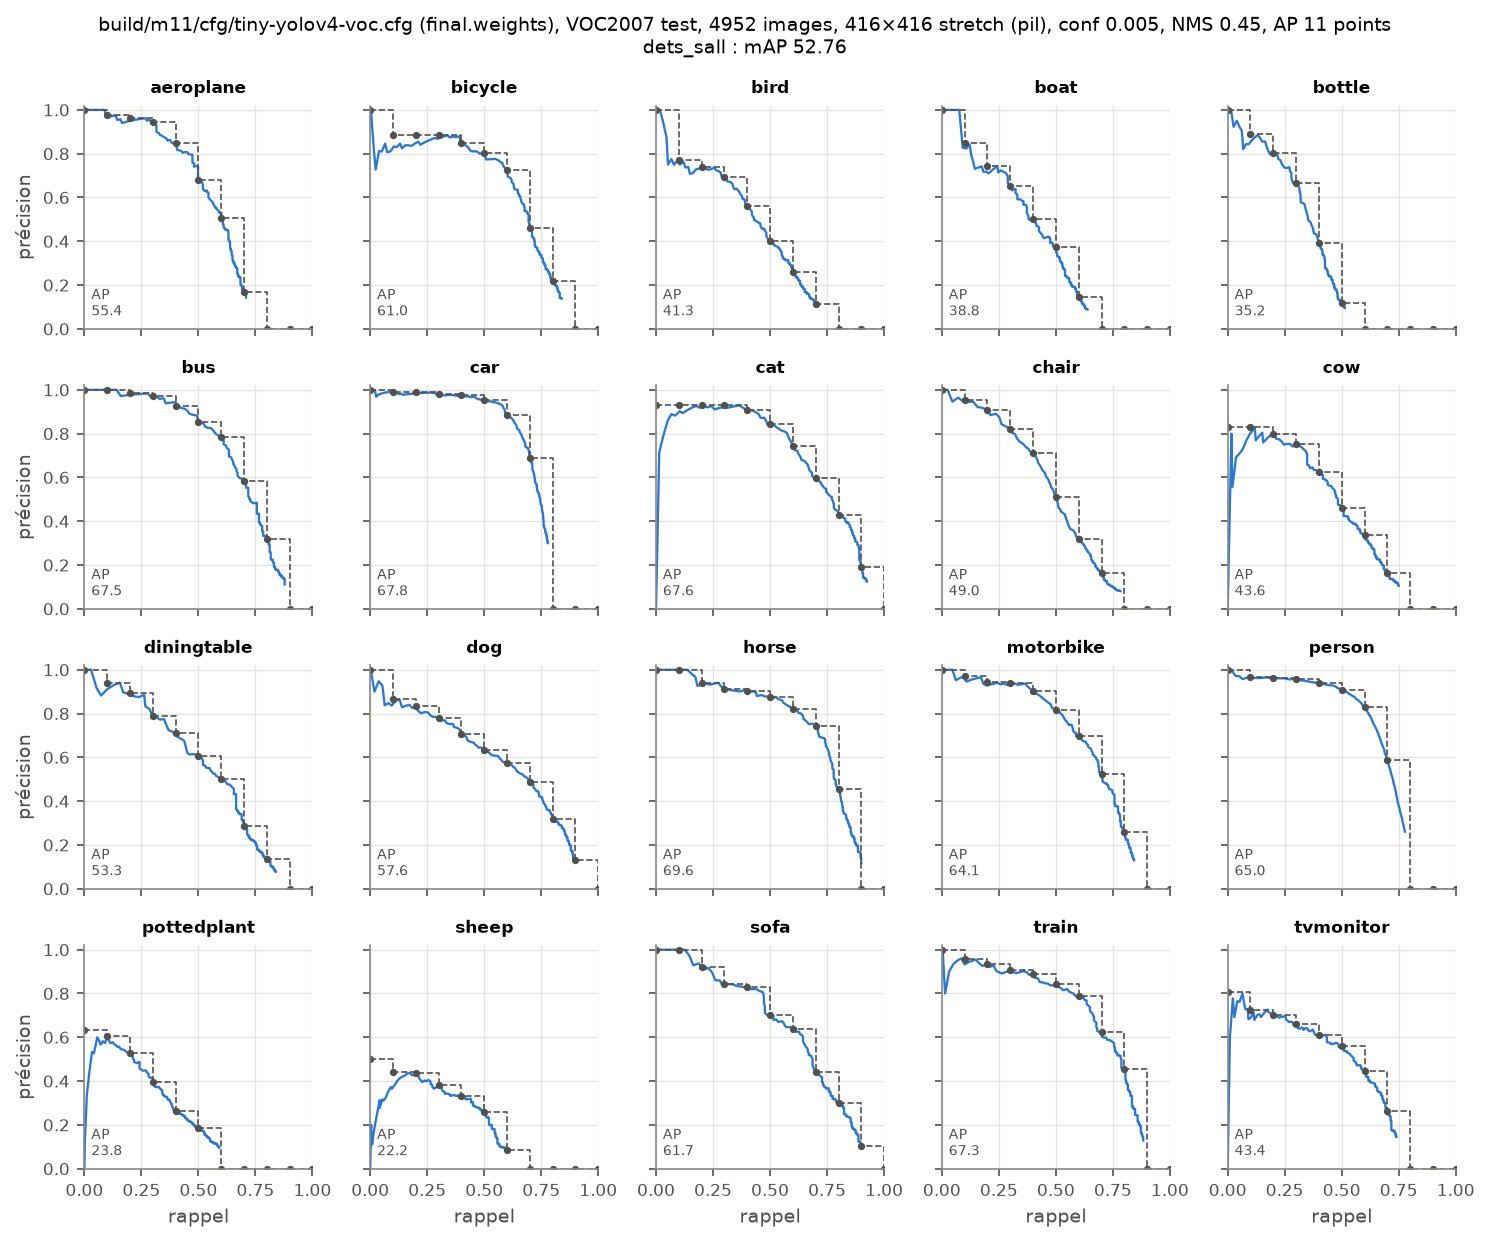

In [5]:
print(f"{SUBSET or 'toutes les'} images : palier "
      f"{palier(SUBSET or SPLIT_IMAGES.get(DATASET))} (règles de M12)")
if CHOSEN is not None:
    EVAL_DIR = Path(RUNS_DIR, "eval", CHOSEN.name)
    runs.evaluate(CHOSEN, NET, DATASET, RESIZE, SUBSET, METRIC, SPLIT, SIZE,
                  DATA_ROOT, out_dir=EVAL_DIR, jobs=JOBS)
    map_float = EVAL_DIR / f"map_float_s{SUBSET or 'all'}.md"
    dets = EVAL_DIR / f"dets_s{SUBSET or 'all'}"
else:
    map_float = Path(OUT) / "map_float.md"
    map_float.unlink(missing_ok=True)0
    C.run(C.cmd_eval_voc(NET, WEIGHTS, DATASET, RESIZE, SUBSET, METRIC, SPLIT, SIZE,
                         DATA_ROOT, out=f"{OUT}/dets", markdown=map_float, jobs=JOBS))
    dets = Path(OUT, "dets")
display(Markdown(map_float.read_text()))
for png in sorted(Path(dets, "figures").glob("pr*.png")):
    display(Image.open(png))

## Comparaison des runs (T14.11)

Avec `COMPARE = True`, chaque run trouvé dans `RUNS_DIR` (notebook `_train` et
balayage `_sweep`) est évalué sur les mêmes `SUBSET` images ; une mAP déjà
calculée pour ce `SUBSET` est réutilisée. Le run évalué plus haut se choisit par
`RUN`.

In [6]:
if COMPARE:
    rows = [runs.evaluate(r, NET, DATASET, RESIZE, SUBSET, METRIC, SPLIT, SIZE,
                          DATA_ROOT, out_dir=f"{RUNS_DIR}/eval/{r.name}", jobs=JOBS)
            for r in RUNS]
    display(Markdown(runs.table(rows)))
else:
    print("COMPARE = False : comparaison sautée ; runs trouvés :")
    print(runs.listing(RUNS))

COMPARE = False : comparaison sautée ; runs trouvés :
  train        build\notebooks\voc\tiny-yolov4-voc\final.weights  (2026-10-22 15:37)
  b16-s500     build\notebooks\voc\tiny-yolov4-voc\runs\b16-s500\final.weights  (2026-10-22 13:25)
  b16-sall     build\notebooks\voc\tiny-yolov4-voc\runs\b16-sall\final.weights  (2026-10-22 13:29)
  b32-s500     build\notebooks\voc\tiny-yolov4-voc\runs\b32-s500\final.weights  (2026-10-22 13:38)
  b32-sall     build\notebooks\voc\tiny-yolov4-voc\runs\b32-sall\final.weights  (2026-10-22 13:47)
  b48-s500     build\notebooks\voc\tiny-yolov4-voc\runs\b48-s500\final.weights  (2026-10-22 14:01)
  b48-sall     build\notebooks\voc\tiny-yolov4-voc\runs\b48-sall\final.weights  (2026-10-22 14:16)
  b8-s500      build\notebooks\voc\tiny-yolov4-voc\runs\b8-s500\final.weights  (2026-10-22 13:14)
  b8-sall      build\notebooks\voc\tiny-yolov4-voc\runs\b8-sall\final.weights  (2026-10-22 13:20)


## Volet entier (T14.4)

Activé par `INT8 = True`. Calibration par `tools/calibrate.py` sur le split `calib`
du jeu (échelles et rapport dans `OUT`, pas dans `results/`), puis
`tools/eval_quant.py --variants float,int`. Sur le split complet (`SUBSET = 0`),
palier **N** : compter 12 à 25 min pour VOC2007 test en plus de la calibration.

SUBSET = 0 : split complet, palier N (plusieurs dizaines de minutes)
$ python tools/calibrate.py --net build/m11/cfg/tiny-yolov4-voc.cfg --weights 'build\notebooks\voc\tiny-yolov4-voc\final.weights' --dataset voc --images 500 --out 'build\notebooks\voc\tiny-yolov4-voc\eval\train\calib.json' --markdown 'build\notebooks\voc\tiny-yolov4-voc\eval\train\calibration.md'
128/500 images     12 s
256/500 images     24 s
384/500 images     36 s
500/500 images     47 s
### tiny-yolov4-voc â€” 500 images VOC2007 trainval, choix Â« mse Â»

Erreur quadratique moyenne FP32 / INT8 de la sortie de chaque convolution, pour chaque seuil d'Ã©crÃªtage c (percentile de |x|, s = c/127). **Gras** : seuil retenu.

| Couche | act | MSE p90 | MSE p95 | MSE p99 | MSE p99.9 | MSE p99.99 | MSE max | c retenu | s_y final | Ã©crÃªtÃ© |
|---|---|---|---|---|---|---|---|---|---|---|
| L00 | leaky | 7.99e-01 | 6.56e-01 | 2.90e-01 | 2.69e-02 | **4.23e-03** | 9.56e-03 | p99.99 = 23.4 | 0.1841 | 0.010 % |
| L01 | leaky | 6

4952 images, voc

| classe | flottant | entier | écart |
|---|---|---|---|
| aeroplane | 55.40 | 51.18 | -4.22 |
| bicycle | 61.01 | 62.94 | +1.93 |
| bird | 41.33 | 40.39 | -0.94 |
| boat | 38.77 | 38.47 | -0.30 |
| bottle | 35.24 | 32.97 | -2.27 |
| bus | 67.50 | 67.16 | -0.34 |
| car | 67.77 | 67.58 | -0.19 |
| cat | 67.64 | 67.71 | +0.07 |
| chair | 48.99 | 47.16 | -1.84 |
| cow | 43.58 | 42.20 | -1.39 |
| diningtable | 53.34 | 54.68 | +1.34 |
| dog | 57.57 | 56.75 | -0.83 |
| horse | 69.57 | 71.56 | +1.99 |
| motorbike | 64.09 | 63.40 | -0.68 |
| person | 65.01 | 64.07 | -0.93 |
| pottedplant | 23.75 | 24.15 | +0.39 |
| sheep | 22.17 | 20.33 | -1.84 |
| sofa | 61.71 | 61.27 | -0.44 |
| train | 67.26 | 65.14 | -2.11 |
| tvmonitor | 43.43 | 43.90 | +0.46 |
| **mAP** | **52.76** | **52.15** | -0.61 |

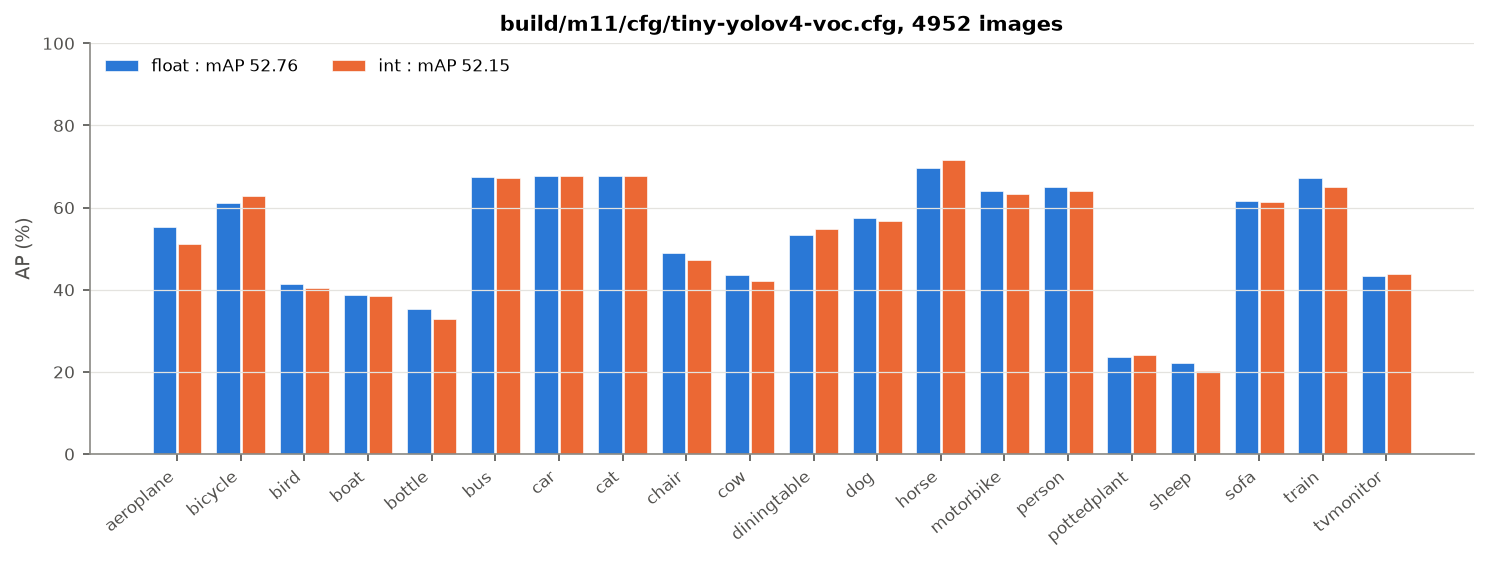

In [7]:
map_int = None
if INT8:
    if not SUBSET:
        print("SUBSET = 0 : split complet, palier N (plusieurs dizaines de minutes)")
    calib = Path(OUT) / "calib.json"
    C.run(C.cmd_calibrate(NET, WEIGHTS, DATASET, calib, Path(OUT) / "calibration.md",
                          CALIB_IMAGES, data_root=DATA_ROOT))
    map_int = Path(OUT) / f"map_{RESIZE}_{SUBSET or 'complet'}.json"
    HW_DIR = Path(OUT) / "hw"  # détections entières par image, pour le volet matériel
    HW_DIR.mkdir(parents=True, exist_ok=True)
    C.run(C.cmd_eval_quant(NET, map_int, "float,int", SUBSET, JOBS, DATASET,
                           weights=WEIGHTS, calib=calib, metric=METRIC, split=SPLIT,
                           size=SIZE, data_root=DATA_ROOT,
                           save_dets=HW_DIR / "int.jsonl" if HW else None))
    d = json.loads(map_int.read_text())
    fl, it = d["results"]["float"], d["results"]["int"]
    rows = ["| classe | flottant | entier | écart |", "|---|---|---|---|"]
    rows += [f"| {c} | {100 * a:.2f} | {100 * b:.2f} | {100 * (b - a):+.2f} |"
             for c, a, b in zip(d["classes"], fl["aps"], it["aps"])]
    rows.append(f"| **mAP** | **{100 * fl['map']:.2f}** | **{100 * it['map']:.2f}** | "
                f"{100 * (it['map'] - fl['map']):+.2f} |")
    display(Markdown(f"{d['images']} images, {d['metric']}\n\n" + "\n".join(rows)))
    for png in sorted((map_int.parent / "figures").glob(f"*{map_int.stem.removeprefix('map_')}*.png")):
        display(Image.open(png))
    if ACT_HIST:
        others = "voc" if DATASET == "voc" else f"voc,{DATASET}"
        C.run(C.cmd_act_hist(NET, WEIGHTS, others, calib, Path(OUT) / "act_hist"))
        display(Image.open(Path(OUT) / "act_hist" / "act_hist.png"))
else:
    print("INT8 = False : volet entier sauté")

## Volet matériel (T8.2, T24.5)

Activé par `HW = True` (avec `INT8 = True` : même calibration, détections entières
de la cellule précédente). Chaîne du profil `coco-v4` de `tools/m11.sh` :

1. `tools/export_model.py` : modèle entier (manifest, blobs) et dumps de 3 images du
   jeu dans `OUT/model` ;
2. golden C++ (`golden_run`) == dumps Python à l'octet, couche par couche et
   détections (`tools/compare_dumps.py`, comme `make golden-check`) ;
3. stade FPGA en C-sim : le noyau HLS compilé sans `ap_int` derrière le driver ARM
   (`yolo_bench`, `tools/bench_sim.sh`), sur les entrées int8 du modèle entier
   (`tools/make_inputs.py`), pour les `SUBSET` premières images ;
4. `tools/map_stades.py` : mAP aux trois stades et égalité image par image entier ==
   C-sim ; `tools/perf_model.py` : cycles et ms du noyau actuel (projection).

Compter ≈ 1 s de C-sim par image et par cœur (C-sim interrompu : relancer la
cellule, les paquets finis sont gardés tant que le modèle exporté ne change pas).

In [8]:
import hashlib
import shutil

map_hw = None
if HW:
    if not INT8:
        raise ValueError("HW = True demande INT8 = True (calibration et détections "
                         "entières)")
    model = Path(OUT) / "model"
    C.run(C.cmd_export(NET, WEIGHTS, calib, model, DATASET, DATA_ROOT))
    for c in C.cmd_cmake("cpp/golden", "build/golden", "golden_run"):
        C.run(c)
    for dump in sorted(p for p in (model / "dumps").iterdir() if p.is_dir()):
        got = HW_DIR / "golden" / dump.name
        C.run(C.cmd_golden_run(model, dump / "input.npy", got))
        C.run(C.cmd_compare_dumps(dump, got))
    # Détections C-sim d'un autre modèle exporté : effacées (sinon reprise).
    blobs = hashlib.sha256(b"".join((model / f).read_bytes() for f in
                                    ("weights.bin", "bias.bin", "requant.bin")))
    stamp = HW_DIR / "model.sha256"
    if not stamp.exists() or stamp.read_text() != blobs.hexdigest():
        shutil.rmtree(HW_DIR / "sim", ignore_errors=True)
        stamp.write_text(blobs.hexdigest())
    C.run(C.cmd_make_inputs(NET, DATASET, SUBSET, HW_DIR, DATA_ROOT))
    shutil.copy(map_int, HW_DIR / "eval_float_int.json")
    for c in C.cmd_cmake("sw", "build/sw-fast", "yolo_bench",
                         "-DACC_NO_APINT -march=native", ["-DSW_BACKEND=sim"]):
        C.run(c)
    C.run(C.cmd_bench_sim(HW_DIR, model, JOBS), env={"BENCH": C.BENCH_FAST})
    map_hw = HW_DIR / "map_stades.md"
    C.run(C.cmd_map_stades(NET, DATASET, HW_DIR, map_hw, SUBSET, DATA_ROOT))
    display(Markdown(map_hw.read_text()))
    C.run(C.cmd_perf_model(model / "manifest.json"))
else:
    print("HW = False : volet matériel sauté")

HW = False : volet matériel sauté


## Résumé

In [9]:
print(map_float.read_text())
if map_int:
    d = json.loads(map_int.read_text())
    for v, r in d["results"].items():
        print(f"{v:6s} mAP {100 * r['map']:.2f} ({d['images']} images)")
if map_hw:
    print(map_hw.read_text().split("## AP")[0])
print(f"sorties : {OUT}/ ; révision {TRACE['rev']}")
print("commandes équivalentes :")
for c in C.HISTORY:
    print("  " + c)

### build/m11/cfg/tiny-yolov4-voc.cfg (final.weights), VOC2007 test, 4952 images, 416×416 stretch (pil), conf 0.005, NMS 0.45, AP 11 points

| Classe | AP |
|---|---|
| aeroplane | 55.4 |
| bicycle | 61.0 |
| bird | 41.3 |
| boat | 38.8 |
| bottle | 35.2 |
| bus | 67.5 |
| car | 67.8 |
| cat | 67.6 |
| chair | 49.0 |
| cow | 43.6 |
| diningtable | 53.3 |
| dog | 57.6 |
| horse | 69.6 |
| motorbike | 64.1 |
| person | 65.0 |
| pottedplant | 23.8 |
| sheep | 22.2 |
| sofa | 61.7 |
| train | 67.3 |
| tvmonitor | 43.4 |
| **mAP** | **52.76** |


float  mAP 52.76 (4952 images)
int    mAP 52.15 (4952 images)
sorties : build/notebooks/voc/tiny-yolov4-voc/eval/train/ ; révision 9a21d9a
commandes équivalentes :
  python tools/eval_voc.py --net build/m11/cfg/tiny-yolov4-voc.cfg --weights 'build\notebooks\voc\tiny-yolov4-voc\final.weights' --dataset voc --resize stretch --subset 0 --out 'build\notebooks\voc\tiny-yolov4-voc\eval\train\dets_sall' --markdown 'build\notebooks\voc\tiny-yolov4-voc\eval